# ¡Feliz Navidad!

Flag: **`SIGMOID_CRUCIO`**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
p = pd.read_csv('../task_spain/purchases.csv')
g = pd.read_csv('../task_spain/office_price_guide.csv')
print(p.shape)
g

(577, 14)


,List_no,Product,Unit,Fair_min_eur,Fair_max_eur,Home_city
0,1,Jamon,kg,35.0,80.0,Salamanca
1,2,Churros,dozen,3.0,7.0,Madrid
2,3,Turron,bar,6.0,15.0,Alicante
3,4,Paella,kit,20.0,45.0,Valencia
4,5,Saffron,g,5.0,12.0,Albacete
5,6,Barquillos,box,4.0,10.0,Madrid


In [2]:
p.head()

,Receipt_id,Date,Pilot_no,City,Shop_type,Product,Quantity,Total_paid_eur,Payment,Shop_rating,Flight_km,Flight_min,Temperature_c,Luggage_kg
0,ES25-00001,2025-12-01,8,Valencia,Souvenir shop,Paella,2.0,296.30,Bizum,3.5,336,54,9.1,17.0
1,ES25-00002,2025-12-01,9,Madrid,Supermarket,Churros,11.0,264.00,Cash,4.5,778,99,3.4,15.8
2,ES25-00003,2025-12-01,11,Salamanca,Specialty store,Jamon,4.1,45.92,Cash,3.0,421,53,6.6,14.6
3,ES25-00004,2025-12-01,9,Salamanca,Market stall,Jamon,4.2,47.46,Card,3.9,517,76,6.8,18.1
4,ES25-00005,2025-12-01,9,Salamanca,Market stall,Jamon,5.7,1225.79,Card,4.1,517,76,6.8,18.8


In [3]:
print('missing:', p.isna().sum().sum(), '| duplicate receipts:', p.Receipt_id.duplicated().sum())
p.describe().T.round(2)

missing: 0 | duplicate receipts: 0


,count,mean,std,min,25%,50%,75%,max
Pilot_no,577.0,11.06,6.08,1.00,6.0,11.0,16.00,21.00
Quantity,577.0,5.99,3.11,1.00,3.6,5.9,8.10,12.00
Total_paid_eur,577.0,203.82,335.88,1.25,16.4,76.9,235.62,2180.53
Shop_rating,577.0,4.11,0.44,2.80,3.8,4.1,4.40,5.00
Flight_km,577.0,1054.99,456.62,266.00,618.0,1007.0,1495.00,1897.00
Flight_min,577.0,112.84,38.58,42.00,77.0,112.0,146.00,184.00
Temperature_c,577.0,7.59,4.24,-5.70,4.5,7.6,10.70,21.00
Luggage_kg,577.0,16.24,3.28,7.70,13.9,16.2,18.40,26.20


## EDA

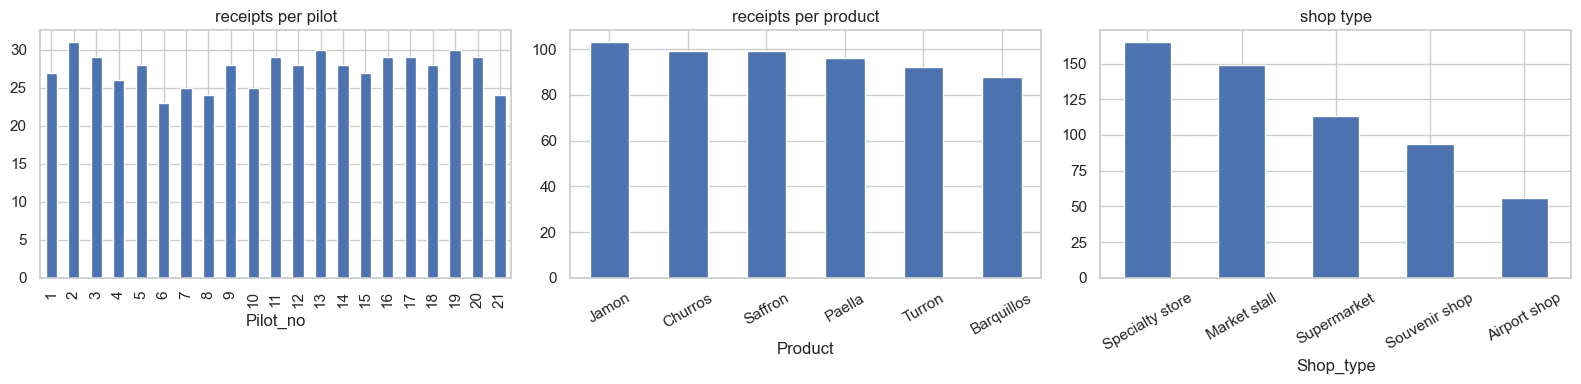

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
p.Pilot_no.value_counts().sort_index().plot.bar(ax=ax[0], title='receipts per pilot')
p.Product.value_counts().plot.bar(ax=ax[1], title='receipts per product', rot=30)
p.Shop_type.value_counts().plot.bar(ax=ax[2], title='shop type', rot=30)
plt.tight_layout(); plt.show()

In [5]:
pd.crosstab(p.Product, p.City)

City,Albacete,Alicante,Madrid,Salamanca,Valencia
Product,,,,,
Barquillos,0,0,88,0,0
Churros,0,0,99,0,0
Jamon,0,0,0,103,0
Paella,0,0,0,0,96
Saffron,99,0,0,0,0
Turron,0,92,0,0,0


Every product is bought in every kind of city, not only its home city.

## Price per unit

In [6]:
d = p.merge(g, on='Product')
d['unit_price'] = d.Total_paid_eur / d.Quantity
d['fair'] = d.unit_price.between(d.Fair_min_eur, d.Fair_max_eur)
d['verdict'] = np.select([d.unit_price < d.Fair_min_eur, d.unit_price > d.Fair_max_eur],
                         ['fake', 'tourist trap'], 'fair')
d.verdict.value_counts()

verdict
tourist trap    270
fake            230
fair             77
Name: count, dtype: int64

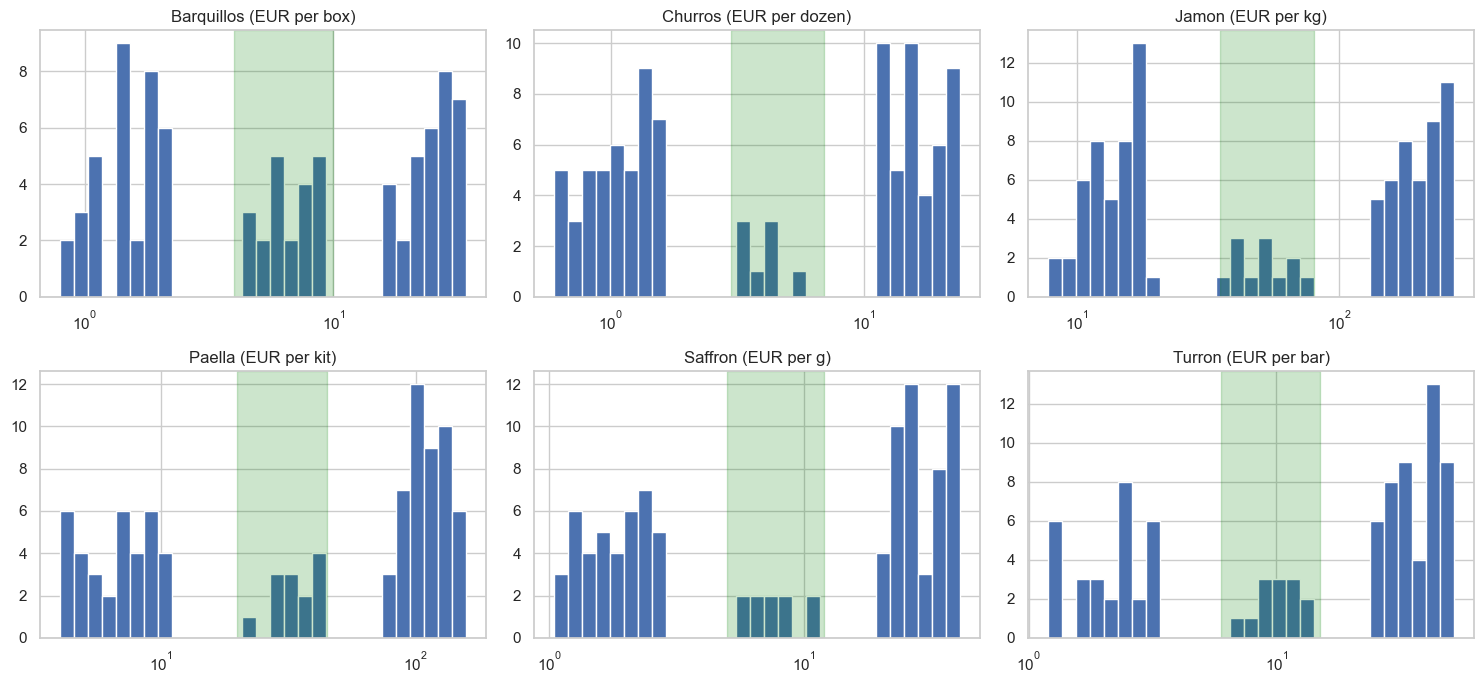

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (prod, s) in zip(axes.flat, d.groupby('Product')):
    lo, hi = s.Fair_min_eur.iloc[0], s.Fair_max_eur.iloc[0]
    ax.hist(s.unit_price, bins=np.logspace(np.log10(s.unit_price.min()), np.log10(s.unit_price.max()), 30))
    ax.axvspan(lo, hi, color='green', alpha=0.2)
    ax.set_xscale('log'); ax.set_title(f'{prod} (EUR per {s.Unit.iloc[0]})')
plt.tight_layout(); plt.show()

Green = fair range. Most receipts are fakes or traps; only 77 of 577 are fair.

In [8]:
pd.crosstab(d.verdict, d.City == d.Home_city, colnames=['bought in home city'])

bought in home city,True
verdict,
fair,77
fake,230
tourist trap,270


All fair receipts were bought in the product's home city.

## Columns that don't matter

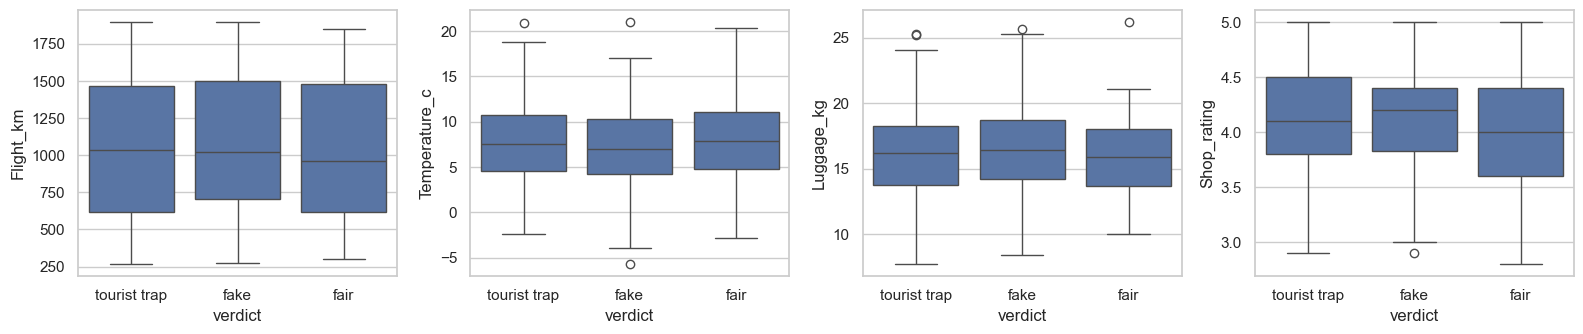

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, c in zip(axes, ['Flight_km', 'Temperature_c', 'Luggage_kg', 'Shop_rating']):
    sns.boxplot(d, x='verdict', y=c, ax=ax)
plt.tight_layout(); plt.show()

Flight, weather, luggage and shop rating look the same for fair and unfair receipts.

## The board

One column per pilot, one row per item on the office list (`List_no` 1 at the top), a cell is filled if that pilot brought that item at a fair price.

In [10]:
fair = d[d.fair]
board = pd.crosstab(fair.List_no, fair.Pilot_no).reindex(index=range(1, 7), columns=range(1, 22), fill_value=0)
board

Pilot_no,1,2,3,4,5,6,7,8,9,10,...,12,13,14,15,16,17,18,19,20,21
List_no,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,1,1,0,0,0,0,...,0,1,2,2,0,0,0,2,2,1
2,0,0,0,0,2,0,2,0,0,0,...,0,1,0,0,0,1,0,1,0,1
3,1,1,1,0,1,0,1,0,1,0,...,0,2,0,0,0,0,0,1,0,2
4,1,0,0,0,2,1,0,0,2,0,...,0,1,0,0,0,1,0,1,0,2
5,1,0,0,0,1,0,1,0,1,0,...,0,1,0,0,0,2,0,1,0,1
6,1,1,2,0,1,0,1,0,1,2,...,0,2,2,2,0,1,0,1,1,2


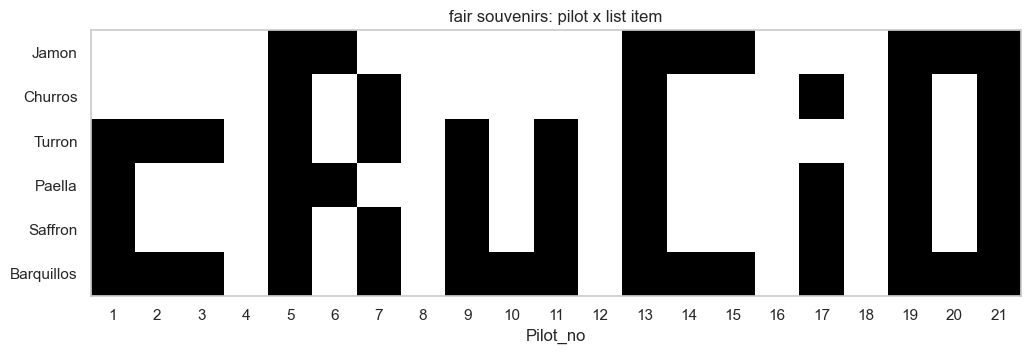

In [11]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.imshow(board > 0, cmap='Greys', aspect='equal')
ax.set_xticks(range(21), range(1, 22)); ax.set_yticks(range(6), g.sort_values('List_no').Product)
ax.set_xlabel('Pilot_no'); ax.grid(False)
ax.set_title('fair souvenirs: pilot x list item')
plt.savefig('board.png', dpi=150, bbox_inches='tight'); plt.show()

In [12]:
for r in range(1, 7):
    print(''.join('#' if board.loc[r, c] else '.' for c in range(1, 22)))

....##......###...###
....#.#.....#...#.#.#
###.#.#.#.#.#.....#.#
#...##..#.#.#...#.#.#
#...#.#.#.#.#...#.#.#
###.#.#.###.###.#.###


Pilots 4, 8, 12, 16 and 18 bring nothing fair, so they split the board into letters: **c R u C i O** → `CRUCIO`.